# Loading data

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from random import randint

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

def normalize(input_array):
    min_val = np.min(input_array)
    max_val = np.max(input_array)
    
    return (input_array - min_val) / (max_val - min_val)

def standardize(input_array):
    return (input_array - np.mean(input_array)) / (np.std(input_array) + 1e-5)
def mimic_standardize(input_array, mimic_mean, mimic_std):
    return (input_array - mimic_mean) / (mimic_std + 1e-5)

# data import

data_in = np.genfromtxt("db_inputs1.csv", delimiter=",", dtype=np.float32)
data_out = np.genfromtxt("db_outputs1.csv", delimiter=",", dtype=np.float32)
nb_data = data_in.shape[0]
  
def stack_tensor(input_np_array, n):
    output_np = np.reshape(input_np_array, (input_np_array.shape[0], input_np_array.shape[1] // n, n))
    return torch.tensor(output_np, dtype=torch.float32)

data_in_torch = stack_tensor(data_in, 4)
data_out_torch = stack_tensor(data_out, 2)

Normalizing accordingly to training data

In [27]:
nb_data = data_in_torch.size(0)
train_size = int(0.90*nb_data)
val_size = int(0.00*nb_data)
test_size = int(0.10*nb_data)

input_data = mimic_standardize(data_in_torch, torch.tensor([-0.0205,  0.0014,  0.0000,  0.0000]), torch.tensor([6.4559, 0.4590, 0.0000, 0.0000]))
output_data = mimic_standardize(data_out_torch, torch.tensor([-9.9011,  0.0310]), torch.tensor([20.6719, 10.7658]))

# Testing via Torch model

In [28]:
class ModelNN(nn.Module):
    def __init__(
        self,
        input_size: int = 1,
        output_size: int = 1,
        rnn_type: str = "RNN",  # "RNN", "LSTM", "GRU"
        hidden_size: int = 16,
        num_layers: int = 1,
        dropout: float = 0.0
    ):
        super().__init__()
        
        # Select and initialize the RNN type
        if rnn_type.upper() == "LSTM":
            self.rnn = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                dropout=dropout if num_layers > 1 else 0.0,
                batch_first=True
            )
        elif rnn_type.upper() == "GRU":
            self.rnn = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                dropout=dropout if num_layers > 1 else 0.0,
                batch_first=True
            )
        elif rnn_type.upper() == "RNN":
            self.rnn = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                nonlinearity='tanh',
                dropout=dropout if num_layers > 1 else 0.0,
                batch_first=True
            )
        
        self.head = nn.Linear(hidden_size, output_size)
        
    def forward(self, x, h=None):
        out, h_new = self.rnn(x, h)
        return self.head(out), h_new
    
hidden_layer_size = 64

model = ModelNN(4, 2, "RNN", hidden_layer_size, 1)
model.load_state_dict(torch.load("rnn_model_thrust_speeds_best.pt", weights_only=True))


<All keys matched successfully>

# Computing max errors of the model against test data

In [29]:
mean_distances = []
max_distances = []

distances = []

idx_measure = 0

for idx in range(train_size+val_size, nb_data):
    full_sequence = input_data[idx].unsqueeze(0)
    h = torch.zeros((1, 1, hidden_layer_size))

    outputs_list = []
    for t in range(full_sequence.size(1)):
        x_step = full_sequence[:, t:t+1, :]
        
        out, h = model(x_step, h)
        outputs_list.append(out)
        
    outputs_cat = torch.cat(outputs_list, axis=1)
    distances.append(np.abs(outputs_cat[0].detach().numpy() - output_data[idx].detach().numpy()))
    
    mean_distances.append(torch.mean(torch.abs(outputs_cat[0][:, idx_measure].detach() - output_data[idx][:, idx_measure].detach())))
    max_distances.append(torch.max(torch.abs(outputs_cat[0][:, idx_measure].detach() - output_data[idx][:, idx_measure].detach())))

distances = np.stack(distances, axis=0)
mean_distances = np.array(mean_distances)
max_distances = np.array(max_distances)

distances.shape, mean_distances.shape, max_distances.shape

((500, 161, 2), (500,), (500,))

In [30]:
print(np.sum(np.isnan(distances)))

0


Text(0.5, 1.0, 'Average error across time, wdot_z')

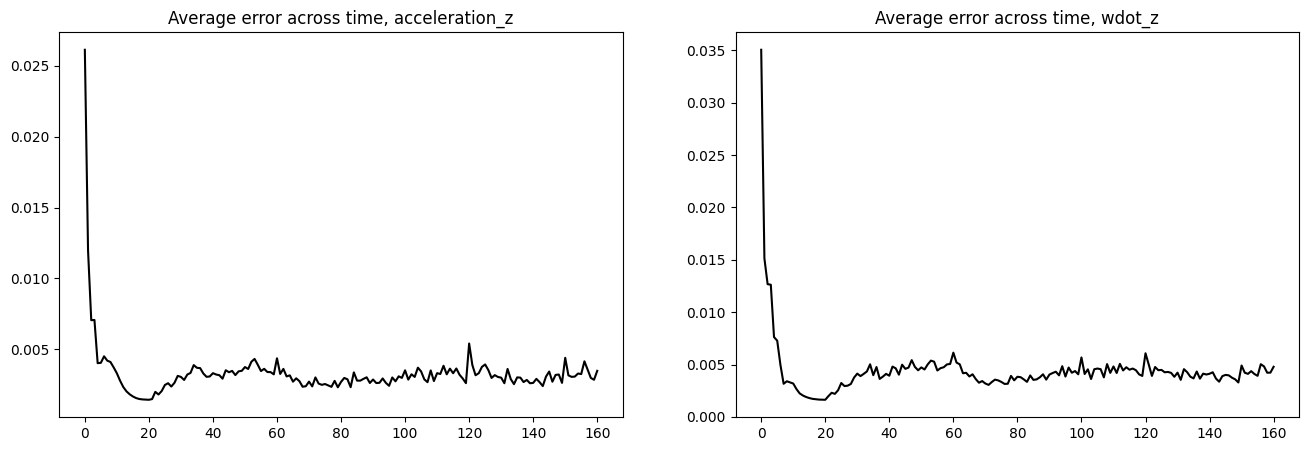

In [40]:
average_on_test = np.mean(distances, axis=0)
fig, axes = plt.subplots(1, 2)
fig.set_figheight(5)
fig.set_figwidth(16)

axes[0].plot(average_on_test[:, 0], c="black")
axes[0].set_title("Average error across time, acceleration_z")
axes[1].plot(average_on_test[:, 1], c="black")
axes[1].set_title("Average error across time, wdot_z")

(array([11., 14., 24., 24., 43., 38., 38., 26., 31., 34., 26., 23., 12.,
        24., 17., 17.,  6.,  6.,  6.,  6.,  6.,  4.,  8.,  2.,  1.,  2.,
         2.,  3.,  3.,  2.,  3.,  5.,  3.,  3.,  2.,  1.,  1.,  1.,  4.,
         0.,  0.,  1.,  1.,  0.,  0.,  1.,  0.,  1.,  0.,  2.,  0.,  1.,
         1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  1.,  0.,
         0.,  0.,  1.,  0.,  0.,  0.,  1.,  1.,  1.,  0.,  0.,  1.,  1.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([0.01529318, 0.01815948, 0.02102578, 0.02389207, 0.02675837,
        0.02962467, 0.03249096, 0.03535726, 0.03822356, 0.04108985,
        0.04395615, 0.04682245, 0.04968874, 0.05255504, 0.05542134,
        0.05828763, 0.06115393, 0.06402023, 0.06688652, 0.06975282,
        0.07261912, 0.07548541, 0.07835171, 0.081218  , 0.0840843 ,
        0.0869506 , 0.0898169 , 0.0926832 , 0.09554949, 0.09841578,
        0.10128208, 0.1041

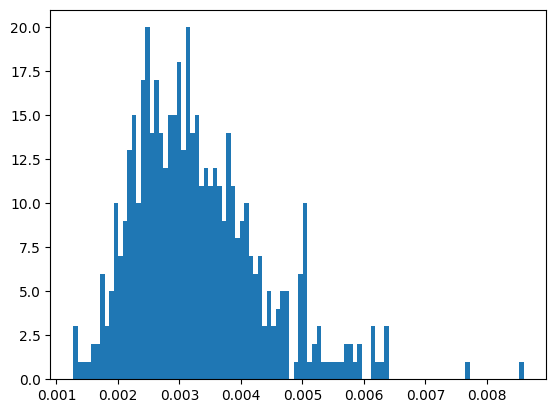

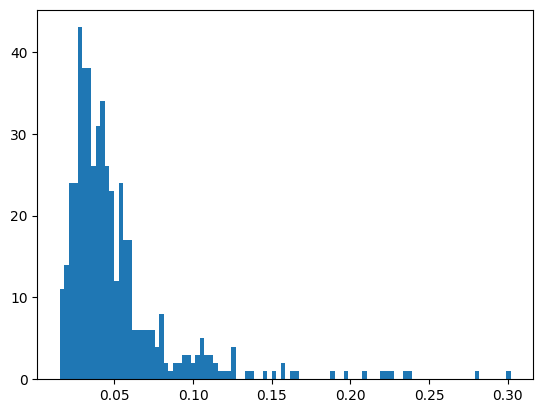

In [32]:
plt.figure()
plt.hist(mean_distances, bins=100)
plt.figure()
plt.hist(max_distances, bins=100)

In [ ]:
for i in range(6):
    print(np.mean(distances[:, :, i]))

0.7527949
0.59739065
0.4186585
0.12544504
0.12132713
0.07531198


Comparing for a given sample

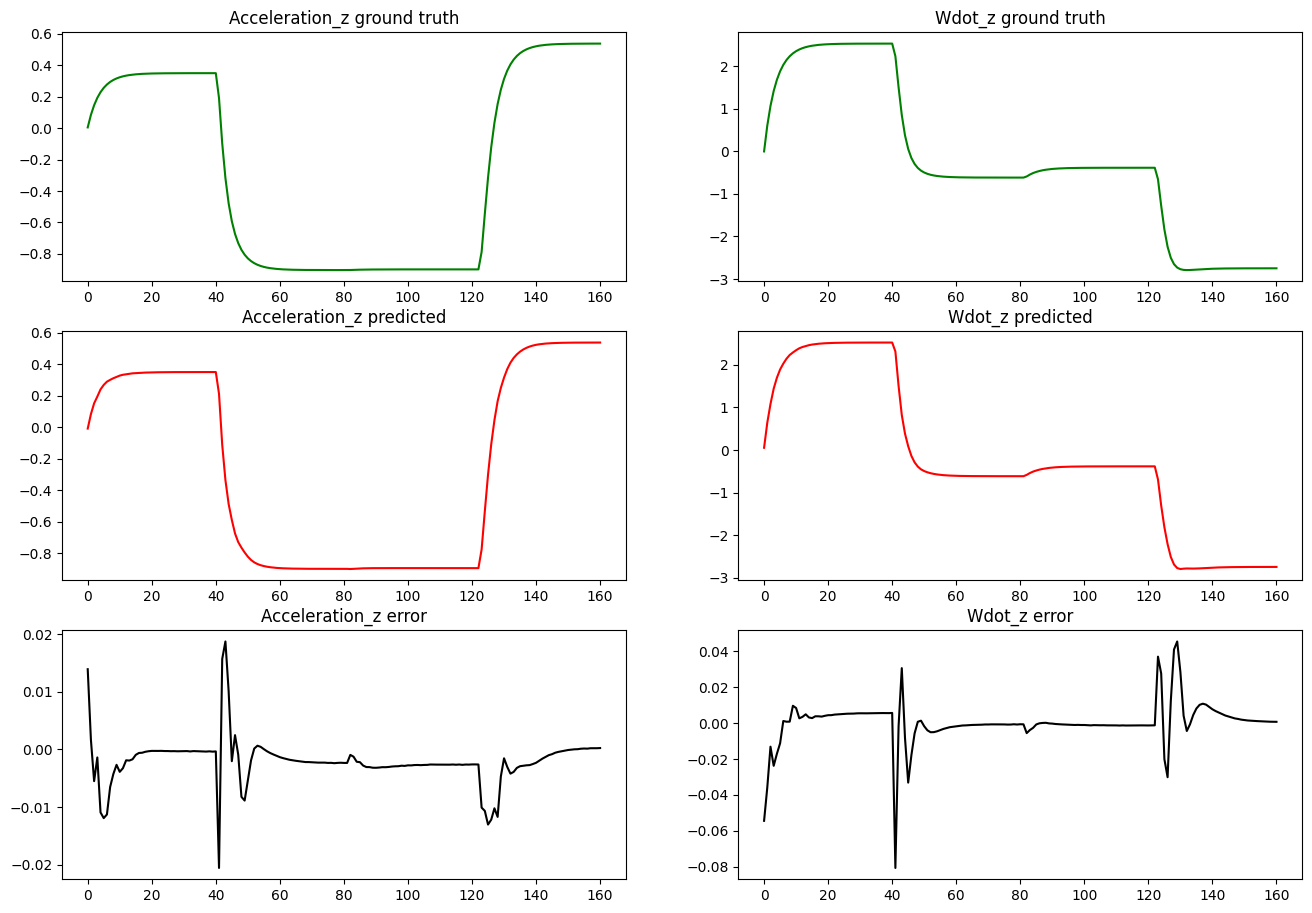

In [41]:
train_rand_idx = randint(0, train_size-1)
test_rand_idx = randint(train_size+val_size, nb_data-1)
idx = test_rand_idx

full_sequence = input_data[idx].unsqueeze(0)
h = torch.zeros((1, 1, hidden_layer_size))

outputs_list = []
for t in range(full_sequence.size(1)):
    x_step = full_sequence[:, t:t+1, :]
    
    out, h = model(x_step, h)
    outputs_list.append(out)
    
outputs_cat = torch.cat(outputs_list, axis=1)

fig, axes = plt.subplots(3, 2)
fig.set_figheight(11)
fig.set_figwidth(16)
plt.plot()

titles = [["Acceleration_z ground truth", "Acceleration_z predicted", "Acceleration_z error"], ["Wdot_z ground truth", "Wdot_z predicted", "Wdot_z error"]]
for i in range(2):
    for j in range(3):
        axes[j, i].set_title(titles[i][j])
    
    axes[0, i].plot(output_data[idx][:, i].detach().numpy(), c="green")
    axes[1, i].plot(outputs_cat[0][:, i].detach().numpy(), c="red")
    axes[2, i].plot(output_data[idx][:, i].detach().numpy() - outputs_cat[0][:, i].detach().numpy(), c="black")

# ONNX version (not working yet)

In [ ]:
import onnx
import onnxruntime

onnx_model = onnx.load("../rnn_model_all_outputs.onnx")
onnx.checker.check_model(onnx_model)

In [ ]:
input_data.size()

torch.Size([1960, 161, 4])

In [ ]:
ort_session = onnxruntime.InferenceSession(
    "../rnn_model_all_outputs.onnx", providers=["CPUExecutionProvider"]
)

input_names = [inp.name for inp in ort_session.get_inputs()]
x_name = input_names[0]
h_name = input_names[1]

train_rand_idx = randint(0, train_size-1)
test_rand_idx = randint(train_size+val_size, nb_data-1)
idx = test_rand_idx

full_sequence = input_data[idx].reshape(1, -1, 4).numpy()

hidden_size = 32
h = np.zeros((1, 1, hidden_size), dtype=np.float32)

onnxruntime_outputs_list = []

for t in range(full_sequence.shape[1]):
    x_step = full_sequence[:, t:t+1, :]
    
    out, h = ort_session.run(
        None, 
        {x_name: x_step, h_name: h}
    )
    onnxruntime_outputs_list.append(out)

onnxruntime_outputs = np.concatenate(onnxruntime_outputs_list, axis=1)

plt.plot(input_data[idx].numpy(), c="blue", alpha=0.3)
plt.plot(output_data[idx].numpy(), c="green", alpha=0.5)
plt.plot(onnxruntime_outputs[0], c="red", alpha=0.7)

# plt.plot(output_data[idx] - onnxruntime_outputs[:, :][0][:, 0], c="blue")
plt.show()

InvalidArgument: [ONNXRuntimeError] : 2 : INVALID_ARGUMENT : Got invalid dimensions for input: x for the following indices
 index: 1 Got: 1 Expected: 5
 Please fix either the inputs/outputs or the model.